# 2 · Resolver CartPole con Deep Q-Networks (DQN)

*Secciones del video 1:09 – 2:34 (Solving Cartpole using DQN → Summary).*

## El problema
Un carrito con un palo encima. Cada paso empujas a la izquierda o a la derecha.
Recibes **+1 por cada paso** que el palo sigue de pie. El episodio termina si el palo
se inclina más de ~12° o el carro se sale, y se corta a los **500 pasos** (puntaje máximo).

Estado = 4 números **continuos**: posición, velocidad, ángulo, velocidad angular.
Hay infinitos estados → una tabla Q no sirve.

## La idea de DQN
Reemplazar la tabla por una red neuronal $Q(s, a; \theta)$: entra el estado, salen 2
números (el valor de cada acción). Entrenamos la red para que cumpla la ecuación de Bellman:

$$Q(s,a;\theta) \approx r + \gamma \max_{a'} Q(s', a'; \theta^-)$$

Hacer esto ingenuamente es inestable. El paper de DeepMind (Mnih et al. 2015, punto 6 del
módulo) lo estabilizó con dos trucos:
1. **Replay memory**: guardar transiciones y entrenar con mini-lotes aleatorios →
   rompe la correlación entre pasos consecutivos y reutiliza experiencia.
2. **Red objetivo** $\theta^-$: una copia lenta de la red para calcular el objetivo →
   el "blanco" no se mueve en cada paso.

El código sigue la misma idea del curso (que a su vez es el tutorial oficial de PyTorch),
escrito de forma más corta.

In [1]:
import math
import random
from collections import deque

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

random.seed(0)
torch.manual_seed(0)

env = gym.make("CartPole-v1")
estado, info = env.reset(seed=0)

## La red Q
Un perceptrón de 3 capas: 4 entradas → 128 → 128 → 2 salidas (un Q por acción).
Mucho más chica que la CNN del paper de Atari, porque aquí el estado ya son 4 números
y no píxeles.

Creamos dos copias: `red` (la que entrenamos) y `red_objetivo` (la copia lenta).

In [2]:
def crear_red():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 128), nn.ReLU(),
        nn.Linear(128, 2),
    )

red = crear_red()
red_objetivo = crear_red()
red_objetivo.load_state_dict(red.state_dict())
print(red)

Sequential(
  (0): Linear(in_features=4, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=2, bias=True)
)


## Hiperparámetros
| nombre | valor | qué hace |
|---|---|---|
| `BATCH_SIZE` | 128 | transiciones por mini-lote |
| `GAMMA` | 0.99 | descuento: el futuro importa mucho |
| `EPS_INICIO → EPS_FIN` | 0.9 → 0.05 | exploración ε-greedy |
| `EPS_DECAY` | 1000 | qué tan rápido decae ε (exponencial, en pasos) |
| `TAU` | 0.005 | velocidad de actualización suave de la red objetivo |
| `LR` | 1e-4 | tasa de aprendizaje de AdamW |

In [3]:
BATCH_SIZE = 128
GAMMA = 0.99
EPS_INICIO = 0.9
EPS_FIN = 0.05
EPS_DECAY = 1000
TAU = 0.005
LR = 1e-4

optimizador = torch.optim.AdamW(red.parameters(), lr=LR, amsgrad=True)
memoria = deque(maxlen=10_000)
pasos = 0

## Elegir acción (ε-greedy con decaimiento exponencial)
$\varepsilon_t = \varepsilon_{fin} + (\varepsilon_{inicio} - \varepsilon_{fin})\, e^{-t/\text{EPS\_DECAY}}$

In [4]:
def elegir_accion(estado):
    epsilon = EPS_FIN + (EPS_INICIO - EPS_FIN) * math.exp(-pasos / EPS_DECAY)
    if random.random() < epsilon:
        return random.randint(0, 1)
    with torch.no_grad():
        q = red(torch.tensor(estado))
    return int(q.argmax())

## Un paso de optimización
1. Saco un mini-lote aleatorio de la memoria.
2. Calculo $Q(s,a)$ con la red (solo la columna de la acción tomada).
3. Calculo el objetivo $r + \gamma \max_{a'} Q_{objetivo}(s',a')$; si el episodio terminó, el futuro vale 0.
4. Pérdida **Huber** (cuadrática para errores chicos, lineal para grandes → robusta a outliers;
   es el equivalente al "recorte del error a [−1, 1]" del paper).
5. Backprop + recorte de gradientes.

In [5]:
def entrenar_paso():
    if len(memoria) < BATCH_SIZE:
        return

    lote = random.sample(memoria, BATCH_SIZE)
    s, a, r, s2, fin = [torch.tensor(np.array(x), dtype=torch.float32) for x in zip(*lote)]

    q = red(s).gather(1, a.long().unsqueeze(1)).squeeze(1)
    with torch.no_grad():
        objetivo = r + GAMMA * red_objetivo(s2).max(1).values * (1 - fin)

    perdida = nn.functional.smooth_l1_loss(q, objetivo)
    optimizador.zero_grad()
    perdida.backward()
    torch.nn.utils.clip_grad_value_(red.parameters(), 100)
    optimizador.step()

## Ciclo de entrenamiento
En cada paso: actuar → guardar transición → optimizar → mover la red objetivo un poquito
hacia la red principal: $\theta^- \leftarrow \tau\theta + (1-\tau)\theta^-$ (*soft update*).
(El paper original copiaba la red completa cada C pasos; el soft update es una variante
más suave que hace lo mismo.)

Ojo: guardamos `terminated` y no `truncated`. Si el episodio se cortó a los 500 pasos,
el palo seguía de pie y el futuro **sí** tiene valor.

In [6]:
duraciones = []

for episodio in range(600):
    estado, info = env.reset()
    done = False
    t = 0
    while not done:
        accion = elegir_accion(estado)
        estado2, reward, terminated, truncated, info = env.step(accion)
        memoria.append((estado, accion, reward, estado2, terminated))
        estado = estado2
        pasos += 1
        t += 1
        done = terminated or truncated

        entrenar_paso()

        # soft update de la red objetivo
        for p_obj, p in zip(red_objetivo.parameters(), red.parameters()):
            p_obj.data.copy_(TAU * p.data + (1 - TAU) * p_obj.data)

    duraciones.append(t)
    if (episodio + 1) % 50 == 0:
        print(f"episodio {episodio + 1}: promedio {np.mean(duraciones[-50:]):.1f}")

episodio 50: promedio 16.0


episodio 100: promedio 11.4


episodio 150: promedio 11.3


episodio 200: promedio 162.7


episodio 250: promedio 227.2


episodio 300: promedio 229.9


... (2 outputs left out)

episodio 450: promedio 500.0


episodio 500: promedio 500.0


episodio 550: promedio 500.0


episodio 600: promedio 500.0


## Visualizar el entrenamiento
Duración de cada episodio (= puntaje) y su promedio móvil de 100 episodios.
Es normal que la curva sea serrucho: DQN es famoso por "olvidar" y recuperarse.

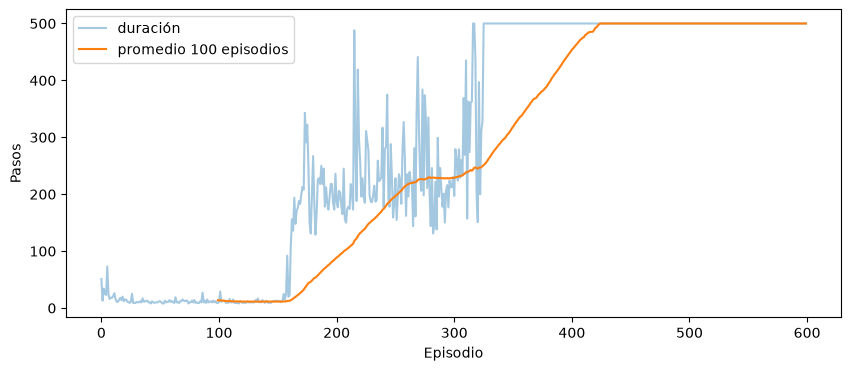

In [7]:
promedio = np.convolve(duraciones, np.ones(100) / 100, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(duraciones, alpha=0.4, label="duración")
plt.plot(range(99, len(duraciones)), promedio, label="promedio 100 episodios")
plt.xlabel("Episodio")
plt.ylabel("Pasos")
plt.legend()
plt.show()

## Evaluación sin exploración
Política 100 % greedy: $\pi(s) = \arg\max_a Q(s,a;\theta)$, 20 episodios con semillas nuevas.

In [8]:
def mejor_accion(estado):
    with torch.no_grad():
        return int(red(torch.tensor(estado)).argmax())

puntajes = []
for i in range(20):
    estado, info = env.reset(seed=1000 + i)
    total = 0
    done = False
    while not done:
        estado, reward, terminated, truncated, info = env.step(mejor_accion(estado))
        total += reward
        done = terminated or truncated
    puntajes.append(total)

print("Puntaje promedio:", np.mean(puntajes))
torch.save(red.state_dict(), "cartpole_dqn.pt")

Puntaje promedio: 500.0


## Ver al agente jugar
Grabamos un episodio como GIF (`render_mode="rgb_array"` devuelve cada cuadro como imagen).

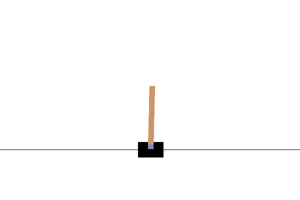

In [9]:
from PIL import Image
from IPython.display import Image as MostrarImagen

env_video = gym.make("CartPole-v1", render_mode="rgb_array")
estado, info = env_video.reset(seed=7)
cuadros = []

for _ in range(300):
    cuadros.append(Image.fromarray(env_video.render()).resize((300, 200)))
    estado, reward, terminated, truncated, info = env_video.step(mejor_accion(estado))
    if terminated or truncated:
        break

cuadros[0].save("cartpole_dqn.gif", save_all=True, append_images=cuadros[1::2], duration=40, loop=0)
MostrarImagen(filename="cartpole_dqn.gif")

## Resumen (video 2:29)
- Estado continuo → aproximamos $Q$ con una red neuronal (**VFA** de Powell, ahora con
  aproximador no lineal).
- **Replay memory** + **red objetivo** = los dos ingredientes del paper DQN que hacen
  estable el entrenamiento.
- Se mantiene ε-greedy para explorar; la pérdida Huber hace robusto el aprendizaje.
- El mismo código (cambiando la red por una CNN y el estado por píxeles) es lo que jugó
  49 juegos de Atari a nivel humano en el paper de Nature.

**Cosas para experimentar**: cambiar `TAU`, `LR`, el tamaño de la red, o quitar la red
objetivo (`red_objetivo = red`) y ver qué tan inestable se vuelve.